# AnoDDPM smoke test: local Jupyter + Modal

This notebook runs locally as a control and reporting surface. The training function runs on Modal's T4 GPU, reads the pinned private dataset, and writes its artifacts to the private Hugging Face model repository. The notebook then downloads only aggregate run metadata and metrics into the ignored local runs/ folder and renders them inline. Saving the notebook keeps the cell outputs in this local .ipynb file.

**Executing the run cell starts a real, billed Modal smoke job.** The bounded config is one epoch on at most 128 normal training samples and 16 validation samples. It does not use the held-out test split and is not a research result or the agreed primary DDPM experiment.

One-time setup from the repository root, in the same Python environment as this notebook:

    python -m pip install -e ".[cloud,hub,train,notebook]"
    modal setup
    jupyter lab notebooks/anoddpm_modal_local.ipynb

The Modal account needs access to the existing huggingface Secret. The local .env needs a read-capable HF_TOKEN (or a local Hugging Face login) to fetch the private aggregate artifacts. The token is read at runtime and is never displayed or embedded in this notebook. The Modal job uses the token stored in the Modal Secret for dataset access and uploads.

In [1]:
import json
import os
import secrets
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import dotenv_values
from huggingface_hub import get_token, hf_hub_download
from IPython.display import Markdown, display

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/dacn/cloud/modal_train.py").is_file()
)
SOURCE_ROOT = ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

MODAL_CLI = shutil.which("modal")
if MODAL_CLI is None:
    raise RuntimeError(
        "Modal CLI is not available in this notebook's Python environment. "
        "Install the cloud extra and run modal setup."
    )

print("Repository root found.")
print("Modal CLI is available.")

Repository root found.
Modal CLI is available.


## Run a bounded job

The notebook starts the repository's existing Modal CLI entrypoint. This keeps the same code path used from the terminal and streams the Modal logs into this cell. Each execution creates a unique run ID.

In [2]:
DATASET_REPO_ID = "dacn-bmad-team/bmad-flair-patient-disjoint-v1"
DATASET_REVISION = "350c74f2313e4e73ca65e7ffc6e9dcf74040b3b7"
MODEL_REPO_ID = "dacn-bmad-team/dacn-runs"
TRAINER = "dacn.training.anoddpm:train"
SMOKE_CONFIG = {
    "seed": 17,
    "epochs": 1,
    "batch_size": 1,
    "base_channels": 32,
    "maximum_training_timestep": 100,
    "validation_reconstruction_steps": 25,
    "max_train_samples": 128,
    "max_validation_samples": 16,
}

# Leave as None to start a fresh Modal job. Set a completed Modal result dict
# here only when you want to re-render artifacts from an existing run.
REUSE_COMPLETED_RUN = None

## Launch Modal and show the run result

The notebook starts the repository's Modal CLI entrypoint and streams its training logs into this cell. Each execution creates a unique run ID. Set REUSE_COMPLETED_RUN to a previous result only to inspect its saved output again without launching another GPU job.

In [3]:
if REUSE_COMPLETED_RUN is not None:
    RUN_RESULT = REUSE_COMPLETED_RUN
    RUN_ID = RUN_RESULT["run_id"]
    print(f"Reusing completed Modal run: {RUN_ID}")
else:
    RUN_ID = (
        "anoddpm-local-smoke-"
        + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        + "-"
        + secrets.token_hex(2)
    )
    RESULT_PATH = ROOT / "runs" / "modal_notebook" / f"{RUN_ID}.modal-result.json"
    RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)
    command = [
        MODAL_CLI,
        "run",
        "--quiet",
        "--detach",
        "--write-result",
        str(RESULT_PATH),
        "src/dacn/cloud/modal_train.py",
        "--dataset-repo-id",
        DATASET_REPO_ID,
        "--dataset-revision",
        DATASET_REVISION,
        "--model-repo-id",
        MODEL_REPO_ID,
        "--run-id",
        RUN_ID,
        "--trainer",
        TRAINER,
        "--config-json",
        json.dumps(SMOKE_CONFIG, separators=(",", ":")),
    ]
    child_env = os.environ.copy()
    source_path = str(SOURCE_ROOT)
    child_env["PYTHONPATH"] = os.pathsep.join(
        part for part in (source_path, child_env.get("PYTHONPATH", "")) if part
    )

    print(f"Starting Modal run: {RUN_ID}")
    process = subprocess.Popen(
        command,
        cwd=ROOT,
        env=child_env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        safe_line = line.replace(str(ROOT), "<repo>").replace(ROOT.as_posix(), "<repo>")
        print(safe_line, end="")
    exit_code = process.wait()
    if exit_code != 0:
        raise subprocess.CalledProcessError(exit_code, command)
    if not RESULT_PATH.is_file():
        raise RuntimeError("Modal completed without writing the local launch result.")
    RUN_RESULT = json.loads(RESULT_PATH.read_text(encoding="utf-8"))
    if RUN_RESULT.get("run_id") != RUN_ID or not RUN_RESULT.get("model_revision"):
        raise RuntimeError("Modal returned an incomplete run result.")

display(RUN_RESULT)

Reusing completed Modal run: anoddpm-local-smoke-20261029T055620Z-b71e


{'run_id': 'anoddpm-local-smoke-20261029T055620Z-b71e',
 'dataset_repo_id': 'dacn-bmad-team/bmad-flair-patient-disjoint-v1',
 'dataset_revision': '350c74f2313e4e73ca65e7ffc6e9dcf74040b3b7',
 'model_repo_id': 'dacn-bmad-team/dacn-runs',
 'model_revision': 'a95b40397aae6f11a7ee863aefbb2613f64a1f47',
 'run_url': 'https://huggingface.co/dacn-bmad-team/dacn-runs/tree/a95b40397aae6f11a7ee863aefbb2613f64a1f47/runs/anoddpm-local-smoke-20261029T055620Z-b71e'}

## Fetch safe aggregate outputs and render them locally

This cell downloads only the run manifest, training history, and validation metrics from the immutable Hugging Face model revision returned by Modal. It does not download the checkpoint or any MRI images.

run_manifest.json: 0.00B [00:00, ?B/s]

C:\Users\LG\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LG\.cache\huggingface\hub\models--dacn-bmad-team--dacn-runs. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


training_history.json: 0.00B [00:00, ?B/s]

validation_metrics.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

,epoch,train_loss,seconds,validation_image_ap,validation_image_auroc,validation_image_f1,validation_image_precision,validation_image_recall,validation_image_score,validation_image_threshold_selected_on_validation,validation_pixel_ap,validation_pixel_auroc,validation_pixel_dice_macro_anomalous_slices,validation_pixel_f1_micro,validation_pixel_precision,validation_pixel_recall,validation_pixel_threshold_selected_on_validation,validation_reconstruction_steps,validation_score_direction,validation_validation_slices
0,1,0.104434,40.1,0.674702,0.625,0.75,0.75,0.75,mean_top_1_percent_of_240x240_squared_reconstr...,0.08077,0.025405,0.643928,0.089938,0.049193,0.026105,0.42578,0.00685,25,higher_is_more_anomalous,16


,validation_metric,value
0,image_ap,0.674702
1,image_auroc,0.625
2,image_f1,0.75
3,image_precision,0.75
4,image_recall,0.75
5,image_score,mean_top_1_percent_of_240x240_squared_reconstr...
6,image_threshold_selected_on_validation,0.08077
7,pixel_ap,0.025405
8,pixel_auroc,0.643928
9,pixel_dice_macro_anomalous_slices,0.089938


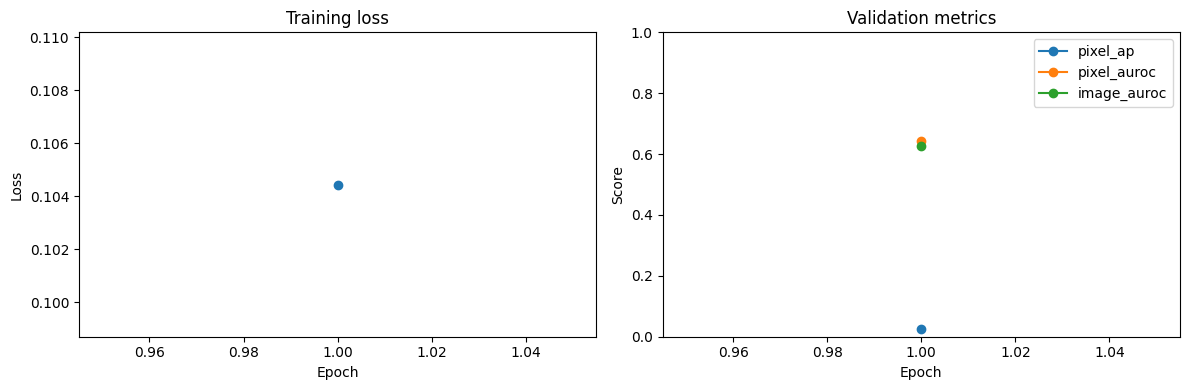

**Status:** completed diagnostic smoke · **GPU:** Tesla T4 · **Best epoch:** 1 · **Dataset revision:** 350c74f2313e4e73ca65e7ffc6e9dcf74040b3b7 · **Model revision:** a95b40397aae6f11a7ee863aefbb2613f64a1f47

Aggregate files and plot saved locally under runs\modal_notebook\anoddpm-local-smoke-20261029T055620Z-b71e.
No held-out test data was passed to the trainer.


In [4]:
local_token = dotenv_values(ROOT / ".env").get("HF_TOKEN") or get_token()
if not local_token:
    raise RuntimeError(
        "A read-capable HF_TOKEN is needed locally. Add it to the ignored .env "
        "file or run hf auth login, then rerun this cell."
    )
MODEL_REVISION = RUN_RESULT.get("model_revision")
if not MODEL_REVISION:
    raise RuntimeError("Modal did not return an immutable Hugging Face model revision.")

ARTIFACT_DIR = ROOT / "runs" / "modal_notebook" / RUN_ID
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
artifact_names = (
    "run_manifest.json",
    "training_history.json",
    "validation_metrics.json",
)
local_artifacts = {}
for name in artifact_names:
    cached_path = hf_hub_download(
        repo_id=MODEL_REPO_ID,
        repo_type="model",
        filename=f"runs/{RUN_ID}/{name}",
        revision=MODEL_REVISION,
        token=local_token,
    )
    local_path = ARTIFACT_DIR / name
    shutil.copy2(cached_path, local_path)
    local_artifacts[name] = local_path

manifest = json.loads(local_artifacts["run_manifest.json"].read_text(encoding="utf-8"))
history = json.loads(local_artifacts["training_history.json"].read_text(encoding="utf-8"))["epochs"]
best = json.loads(local_artifacts["validation_metrics.json"].read_text(encoding="utf-8"))
del local_token

rows = []
for epoch in history:
    row = {
        "epoch": epoch["epoch"],
        "train_loss": epoch["train_loss"],
        "seconds": epoch.get("seconds"),
    }
    row.update({f"validation_{key}": value for key, value in epoch["validation"].items()})
    rows.append(row)
history_table = pd.DataFrame(rows)
display(history_table.round(6))

metrics_table = pd.DataFrame(
    [{"validation_metric": key, "value": value} for key, value in best["metrics"].items()]
)
display(metrics_table.round(6))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_table["epoch"], history_table["train_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
for metric in ("pixel_ap", "pixel_auroc", "image_auroc"):
    column = f"validation_{metric}"
    if column in history_table:
        axes[1].plot(history_table["epoch"], history_table[column], marker="o", label=metric)
axes[1].set(title="Validation metrics", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
axes[1].legend()
figure.tight_layout()
figure.savefig(ARTIFACT_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

display(
    Markdown(
        f"**Status:** completed diagnostic smoke · **GPU:** {manifest['gpu']} · "
        f"**Best epoch:** {best['best_epoch']} · **Dataset revision:** "
        f"{manifest['dataset_revision']} · **Model revision:** {MODEL_REVISION}"
    )
)
print(f"Aggregate files and plot saved locally under {ARTIFACT_DIR.relative_to(ROOT)}.")
print("No held-out test data was passed to the trainer.")